# Genetic Risk Prediction: cis-eQTL Discovery (NBK 2)

This notebook focuses on identifying **cis-eQTLs**. These are SNPs within a gene's local window (±500 kb of the gene body) that statistically associate with that gene's expression level. To do this, we can demonstrate the method on a single gene (COMT) and visualize the result as a LocusZoom-style plot. Then we can scale the pipeline up to one full chromosome (Chromosome 22) as a fast path toward the eventual genome-wide analysis.

To begin, the following prerequisites are required to run this notebook without any errors:

- NBK 1 (`data_wrangling.ipynb`) reviewed, as this NBK assumes the same `data/` layout and NBK 1 provides good context to the analyses within this NBK.
- `data/genotype/LDREF/` populated with the 1000G EUR PLINK filesets (`1000G.EUR.{1..22}.{bed,bim,fam}`)
- `data/phenotype/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt.gz` (Geuvadis expression matrix)
- `data/annotation/gene_annot.txt.gz` (gene annotation table)
- Python environment with `numpy`, `pandas`, `scipy`, `matplotlib`, `bed-reader` installed (see `requirements.txt`)
- `helpers.py` present in the same directory as this notebook

---

### Import statements

In [37]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers

---

### Loading inputs from NBK 1

Specifically, we need the **Geuvadis expression matrix**, the **1000 Genomes EUR genotypes for Chromosome 22**, the **gene annotation**, and the **shared cohort** of individuals present in both genotype and expression datasets.


In [38]:
expression_df = helpers.read_expression()
metadata_columns = ["TargetID", "Gene_Symbol", "Chr", "Coord"]
sample_ids = [column for column in expression_df if column not in metadata_columns]
annotation_df = helpers.read_gene_annotation()
genotype_matrix = helpers.read_genotypes(helpers.ldref_prefix(22))[0]
iids = helpers.read_genotypes(helpers.ldref_prefix(22))[1]
bim_df = helpers.read_genotypes(helpers.ldref_prefix(22))[2]
shared_individuals = sorted(set(str(i) for i in iids) & set(sample_ids))

print(f"Gene expression matrix: {expression_df.shape}")
print(f"Chromosome 22 genotypes: {genotype_matrix.shape[0]} individuals x {genotype_matrix.shape[1]} SNPs")
print(f"Shared cohort: {len(shared_individuals)} individuals")

Gene expression matrix: (23722, 466)
Chromosome 22 genotypes: 489 individuals x 17489 SNPs
Shared cohort: 344 individuals


---

### Understanding cis-eQTL discovery (with COMT as our test gene)

An **expression Quantitative Trait Locus (eQTL)** is a SNP whose genotype correlates with the expression level of some gene across individuals. In particular, a **cis-eQTL** is a local version: SNPs within a **±500 kb window around the gene body**. This is called the cis-window and is used as most SNPs that affect expression do so by altering a nearby regulatory element (promoter, enhancer, splice signal, etc.), so the real signal tends to sit close to the gene.

To find cis-eQTLs, we can fit a simple linear regression per SNP, across the shared cohort of individuals:

$$\text{expression}_i = \alpha + \beta \cdot \text{genotype}_i + \varepsilon_i$$

where `genotype` is coded 0 / 1 / 2 (count of the alternative allele). As such, SNPs with a significantly non-zero β are candidate cis-eQTLs.

For testing, we can use the gene COMT (*catechol-O-methyltransferase*) which has `ENSG00000093010` as its Ensembl ID. COMT breaks down **catecholamines** (dopamine, epinephrine, norepinephrine) in the brain and body, and its most studied polymorphism, **Val158Met (rs4680)**, is linked to differences in cognition, pain sensitivity, and schizophrenia risk.

In [39]:
ensembl = "ENSG00000093010"
comt_row = annotation_df[annotation_df["SYM"] == ensembl].iloc[0]

print(f"Gene: {comt_row['ID']} ({ensembl})")
print(f"Location: Chromosome {comt_row['CHR']}")
print(f"Gene body: {comt_row['START']:,} – {comt_row['STOP']:,}")
print(f"Type: {comt_row['TYPE']}")

Gene: COMT (ENSG00000093010)
Location: Chromosome 22
Gene body: 19,950,941 – 19,967,694
Type: protein_coding


COMT sits on Chromosome 22 (around 19.9 Mb), with its gene body spanning ~17 kb. Its ±500 kb cis-window therefore covers roughly **19.45 Mb to 20.47 Mb** on Chromosome 22, and every SNP from the LDREF panel falling in that ~1 Mb stretch becomes a candidate eQTL to test.

---

### Running the cis-eQTL regression for COMT

To test COMT we can:
1. **Align the genotype matrix** to only the 344 shared individuals (so rows correspond to people who also have expression data)
2. **Pull COMT's expression vector** across those same 344 individuals, in the same order (so rows align)
3. **Identify the cis-SNPs**, which is every Chromosome 22 SNP within ±500 kb of COMT's gene body
4. **Regress expression on each cis-SNP's genotype** and record β, SE, and p-value per SNP

First, aligning the genotyping rows to the shared cohort and pulling COMT's expression vector (steps 1 and 2).


In [40]:
row_index = {iid: i for i, iid in enumerate(iids)}
shared_rows = [row_index[iid] for iid in shared_individuals]
aligned_genotype = genotype_matrix[shared_rows, :]
print(f"Aligned genotype matrix: {aligned_genotype.shape}")

comt_expression_row = expression_df[expression_df["TargetID"].str.startswith(ensembl)].iloc[0]
comt_expression = comt_expression_row[shared_individuals].to_numpy(dtype=float)
print(f"COMT expression vector: {comt_expression.shape}")

Aligned genotype matrix: (344, 17489)
COMT expression vector: (344,)


Now, both have 344 rows (individuals) in matching order. The helper `helpers.eqtl_for_gene` can then be used to identify the cis-SNPs and regress expression on each cis-SNP's genotype (steps 3 and 4).

In [41]:
eqtl_results = helpers.eqtl_for_gene(aligned_genotype, bim_df, comt_expression, start=int(comt_row["START"]), stop=int(comt_row["STOP"]), gene=ensembl)
print(f"cis-SNPs tested: {len(eqtl_results)}")
eqtl_results.sort_values("pval").head()

cis-SNPs tested: 509


,gene,snp,chr,pos,a1,beta,se,pval,neglog10p
263,ENSG00000093010,rs5746847,22,19921003,T,-2.537140,0.641548,0.000093,4.030764
267,ENSG00000093010,rs5748485,22,19923415,A,-2.537140,0.641548,0.000093,4.030764
269,ENSG00000093010,rs5748489,22,19927146,A,-2.537140,0.641548,0.000093,4.030764
259,ENSG00000093010,rs5993875,22,19915326,A,-2.529845,0.641856,0.000098,4.007756
276,ENSG00000093010,rs1544325,22,19931668,A,-2.469365,0.638192,0.000131,3.883762


Each row is one SNP in COMT's cis-window with its chromosomal position, effect size (β), standard error, and p-value.

---

### Visualising the cis-eQTL landscape using a LocusZoom plot

A **LocusZoom plot** shows SNP position on the x-axis and `−log₁₀(p-value)` on the y-axis. This is a way to visualize a region's association signal. Peaks mark SNPs most strongly associated with expression. The dashed red line is the **Bonferroni significance threshold** (`p = 0.05 / n_SNPs`), above which associations remain significant after correcting for multiple testing. The orange band marks COMT's gene body, to show how close the strongest signals sit to the gene.


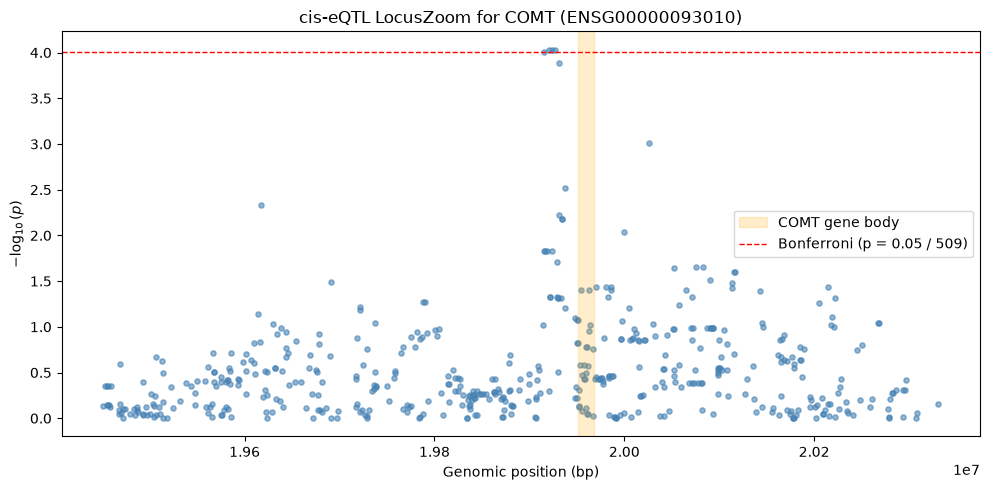

In [42]:
bonferroni_threshold = -np.log10(0.05 / len(eqtl_results))

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(eqtl_results["pos"], eqtl_results["neglog10p"], s=14, alpha=0.6, color="steelblue")
ax.axvspan(comt_row["START"], comt_row["STOP"], color="orange", alpha=0.2, label="COMT gene body")
ax.axhline(bonferroni_threshold, ls="--", color="red", lw=1, label=f"Bonferroni (p = 0.05 / {len(eqtl_results)})")
ax.set(xlabel="Genomic position (bp)", ylabel=r"$-\log_{10}(p)$", title=f"cis-eQTL LocusZoom for COMT ({ensembl})")
ax.legend()
fig.tight_layout()
plt.show()

Every dot is a SNP in the ±500 kb window; its height reflects strength of association with COMT's expression in this cohort. SNPs above the red line are candidate significant cis-eQTLs for COMT.


---

### Scaling up using all protein-coding genes on Chromosome 22

As a fast preview of the eventual genome-wide analysis, we now run the same cis-eQTL regression for every protein-coding gene on Chromosome 22 (~396 genes), then look at the strongest hits across the entire chromosome.

In [43]:
chr22_genes = annotation_df[(annotation_df["CHR"] == 22) & (annotation_df["TYPE"] == "protein_coding")]
print(f"Protein-coding genes on Chromosome 22: {len(chr22_genes)}")

chr22_results = []
for _, gene in chr22_genes.iterrows():
    expression_row = expression_df[expression_df["TargetID"].str.startswith(gene["SYM"])]
    if expression_row.empty:
        continue
    expression_vec = expression_row.iloc[0][shared_individuals].to_numpy(dtype=float)
    if np.all(np.isnan(expression_vec)):
        continue
    gene_eqtls = helpers.eqtl_for_gene(aligned_genotype, bim_df, expression_vec, start=int(gene["START"]), stop=int(gene["STOP"]), gene=gene["SYM"])
    if not gene_eqtls.empty:
        chr22_results.append(gene_eqtls)

chr22_eqtls = pd.concat(chr22_results, ignore_index=True)
print(f"Total SNP-gene tests on Chromosome 22: {len(chr22_eqtls):,}")
chr22_eqtls.sort_values("pval").head()

Protein-coding genes on Chromosome 22: 396
Total SNP-gene tests on Chromosome 22: 162,845


,gene,snp,chr,pos,a1,beta,se,pval,neglog10p
140215,ENSG00000100376,rs104664,22,45711854,G,13.171090,0.485757,3.256798e-87,86.487209
140236,ENSG00000100376,rs6006992,22,45742760,A,13.337077,0.496923,3.509309e-86,85.454778
140250,ENSG00000100376,rs136564,22,45764874,C,13.337077,0.496923,3.509309e-86,85.454778
140248,ENSG00000100376,rs1569413,22,45756081,G,13.337077,0.496923,3.509309e-86,85.454778
140228,ENSG00000100376,rs3827393,22,45736153,G,13.337077,0.496923,3.509309e-86,85.454778


Running the regression across every protein-coding gene on Chromosome 22 produces tens of thousands of SNP-gene tests. The strongest hits (smallest p-values) tend to sit very close to their associated gene, consistent with the cis-regulatory biology outlined earlier.

---

### Saving the results

The per-SNP results for Chromosome 22 can be written as a CSV file so they can be inspected or reported without having to rerun the regression. This is particularly relevant at genome-wide scale, as rerunning the regression would take hours.


In [44]:
output_path = Path("../output/eqtl_results/chr22_eqtl_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
chr22_eqtls.to_csv(output_path, index=False)
print(f"Saved to {output_path}.")

Saved to ..\output\eqtl_results\chr22_eqtl_results.csv.


With the results saved for Chromosome 22, the file can be re-loaded directly for any later summary or visualization. This also holds for a the genome-wide regression with no changes.

---